# Exploratory Data Analysis Project

## Screen Time Impact on Mental Health

1. #### Loading ,Inspecting dataset and planning approach

In [67]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [68]:
df = pd.read_csv("mental_health_screen_time_mildly_messy.csv")


# df = df.drop(columns=['education_level'])

# print(df.head())
print(df.shape)
# print(df.info())
# print(df.describe())




(146, 10)


 ##### Dataset Overview
 By analysing data we found out that our dataset has 146 rows and 9 columns and in which age,daily_screen_time_hours,social_media_hours,sleep_hours,physical_activity_minutes and mental_healh_score are numerical data with daatype float and gender,educaion_level,sress_level and focus_level are string values.


 ##### Questions

 By analyzing this dataset I want to answer the following question
 1. Is there a relationship between daily screen time and mental health score?
 2. Is social media time more strongly related to mental health than other screen time?
 3. How sleep hours are related to focus and stress level
 


#### Cleaning Data and Removing Null Values

In [69]:
# Looking for null values 

print(df.isna().sum())

# filling na in "daily_screen_time_hours " with mean screen time of age 

# avg_screentime = df.groupby("age")["daily_screen_time_hours"].mean()
# avg_screentime[df[""]]


# Dropping NA of sleep hours and mental health score
# df = df.dropna()
# df.isna().sum()

age                          0
gender                       0
education_level              0
daily_screen_time_hours      1
social_media_hours           0
sleep_hours                  1
physical_activity_minutes    0
stress_level                 1
focus_level                  0
mental_health_score          1
dtype: int64


In [70]:
# Droping null where null value of mental_health_score column is missing because the main thing for analysis is missing if only one is missing we can drop it.
#Also dropping null values of stress_level
df = df.dropna(subset=["mental_health_score"])
df = df.dropna(subset=["stress_level"])

# Filling missing values of daily_screen_time_hours , sleep_hours with their mean

df["daily_screen_time_hours"] = df["daily_screen_time_hours"].fillna(
    df.groupby("age")["daily_screen_time_hours"].transform("median")
)

df["sleep_hours"] = df["sleep_hours"].fillna(
    df.groupby("age")["sleep_hours"].transform("median")
)


# Driving a new feature of other screen time which is cruicial
nos = df[df["daily_screen_time_hours"]<= 1]
print(nos)

df["other_screentime_hours"] = df["daily_screen_time_hours"] - df["social_media_hours"]

# print(df.isna().sum())
# print(df.shape)
df.head()

     age  gender education_level  daily_screen_time_hours  social_media_hours  \
30  22.0  Female              UG                      0.2                 3.4   

    sleep_hours  physical_activity_minutes stress_level focus_level  \
30          5.9                       76.0    Very High         Low   

    mental_health_score  
30                 81.6  


,age,gender,education_level,daily_screen_time_hours,social_media_hours,sleep_hours,physical_activity_minutes,stress_level,focus_level,mental_health_score,other_screentime_hours
0,20.0,Male,UG,6.7,3.1,8.4,24.0,Low,Medium,82.1,3.6
1,23.0,Male,PG,7.0,4.4,6.2,60.0,Moderate,Medium,55.9,2.6
2,21.0,Male,PG,8.8,3.1,6.3,1.0,Low,Low,27.8,5.7
3,22.0,Male,UG,5.8,2.0,7.3,45.0,Low,Medium,29.9,3.8
4,18.0,Female,UG,6.1,3.5,8.0,21.0,Low,High,74.0,2.6


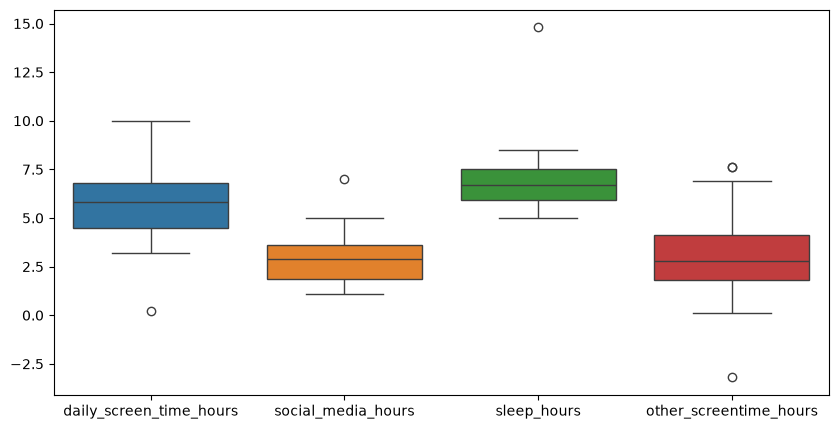

In [71]:
# Finding Outliers

plt.figure(figsize=(10,5))
sns.boxplot(data=df[["daily_screen_time_hours","social_media_hours","sleep_hours","other_screentime_hours"]])

plt.show()

(144, 11)
(142, 11)


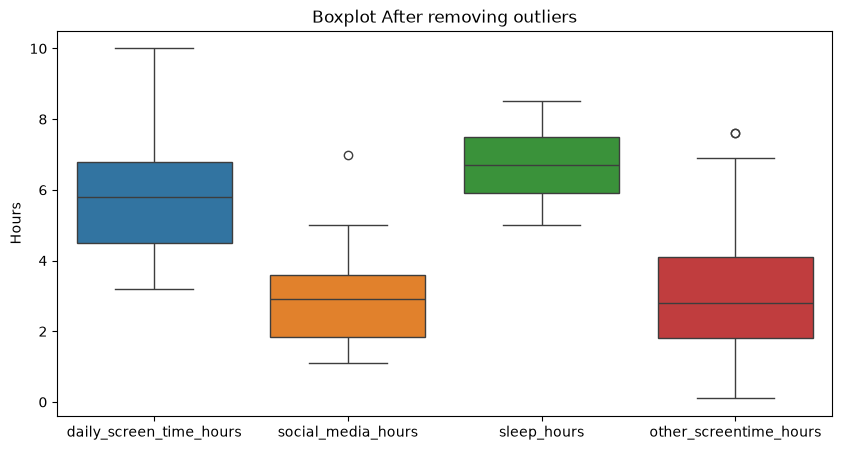

In [72]:
# here we have find the outlier Now we have to remove them
print(df.shape)
df = df[(df["daily_screen_time_hours"]>1) & (df["sleep_hours"]<12) & (df["other_screentime_hours"]>=0)   ]
print(df.shape)

#It has removed two rows we found out by checking shape before and after filtering.
# Boxplot after removing outliers

plt.figure(figsize=(10,5))
sns.boxplot(data=df[["daily_screen_time_hours","social_media_hours","sleep_hours","other_screentime_hours"]])
plt.title("Boxplot After removing outliers")
plt.ylabel("Hours")
plt.show()


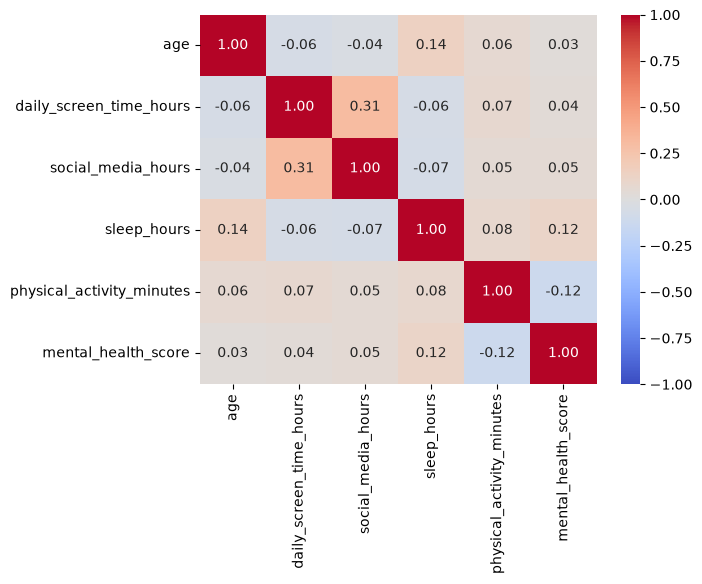

In [73]:
# print(df.head())
corr = df[["age","daily_screen_time_hours","social_media_hours","sleep_hours","physical_activity_minutes","mental_health_score"]].corr()
# print(corr)

plt.Figure(figsize=(9,7))
sns.heatmap(corr,annot=True,vmin=-1 ,vmax=1 ,cmap= "coolwarm",fmt=".2f")
plt.show()


By analyzing the correlation heatmap, I found that most features do not have a strong direct linear relationship with each other. However, some features show weak or slight correlations

### Grouping and Comparing

In [74]:
#Adding a new feaure of screen level
df["screen_level"] = df["daily_screen_time_hours"].apply(
    lambda x: "Low" if x < 4 else ("Medium" if x < 7 else "High"))

stats = df.groupby("screen_level")["mental_health_score"].agg(["mean", "min", "max", "count"])
stats.reindex(["Low","Medium","High"])

,mean,min,max,count
screen_level,,,,
Low,48.427273,23.1,81.5,22
Medium,50.854651,18.2,87.9,86
High,50.729412,19.8,90.2,34


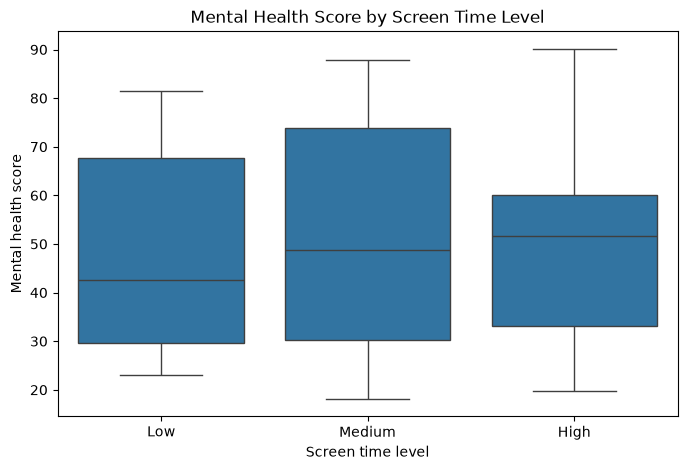

In [75]:
# After creating groups lets create box plot

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="screen_level", y="mental_health_score", order=["Low", "Medium", "High"])
plt.title("Mental Health Score by Screen Time Level")
plt.xlabel("Screen time level")
plt.ylabel("Mental health score")
plt.show()

### Analysis

By doing exploratory data analysis I want to find out how screen time, sleep related to the mental health score

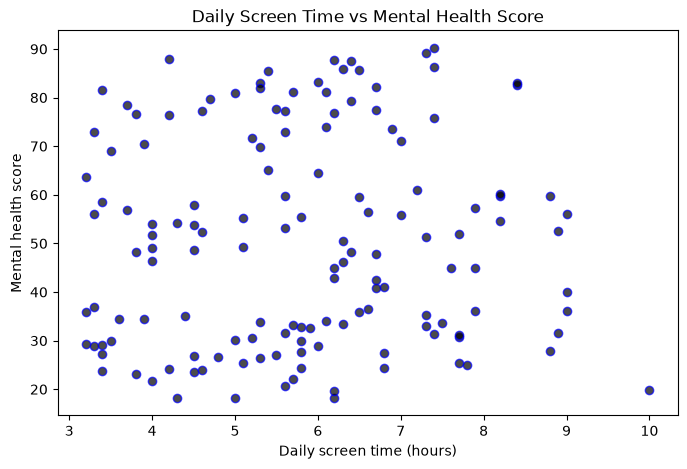

In [76]:
plt.figure(figsize=(8,5))
plt.scatter(df["daily_screen_time_hours"],df["mental_health_score"], color="k", edgecolor="b", alpha=0.7, label="Screen Time")
plt.title("Daily Screen Time vs Mental Health Score")
plt.xlabel("Daily screen time (hours)")
plt.ylabel("Mental health score")
plt.show()

In [77]:
print(df[["daily_screen_time_hours","mental_health_score"]].corr())

                         daily_screen_time_hours  mental_health_score
daily_screen_time_hours                 1.000000             0.035496
mental_health_score                     0.035496             1.000000


**Question 1: Is there a relationship between daily screen time and mental health score?**

The scatter plot shows no clear relationship between daily screen time and mental health score. Scores range from about low to high at both low and high screen time, so screen time does not predict mental health score in this dataset.Also the correlation shows 1 :0.035 which is very small near to zero

## Social Media Vs Other Screen Time

In [78]:
print(df[["social_media_hours","mental_health_score"]].corr())
print(df[["other_screentime_hours","mental_health_score"]].corr())


                     social_media_hours  mental_health_score
social_media_hours             1.000000             0.053705
mental_health_score            0.053705             1.000000
                        other_screentime_hours  mental_health_score
other_screentime_hours                1.000000            -0.003438
mental_health_score                  -0.003438             1.000000


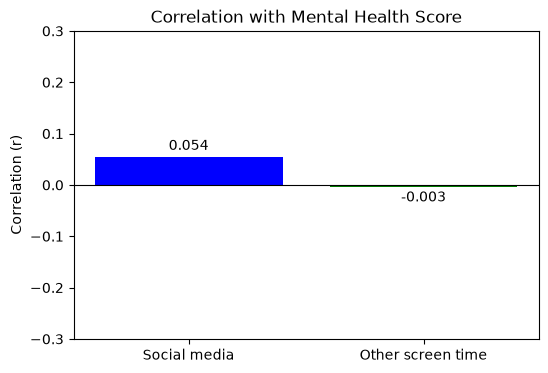

In [79]:
r_social = df["social_media_hours"].corr(df["mental_health_score"])
r_other = df["other_screentime_hours"].corr(df["mental_health_score"])

plt.figure(figsize=(6, 4))
bars = plt.bar(["Social media", "Other screen time"], [r_social, r_other],
               color=["b", "g"])
plt.bar_label(bars, fmt="%.3f", padding=3)  

plt.axhline(0, color="black", linewidth=0.8)
plt.ylim(-0.3, 0.3)
plt.title("Correlation with Mental Health Score")
plt.ylabel("Correlation (r)")
plt.show()

**Question 2: Is social media time more strongly related to mental health score than other screen time?**

Both bars are very close to zero 
so no type of screen time is meaningfully related to mental health score
The small gap between them is too small to matter with 146 people.

## Sleep Hours Relation with Focus and stress level 

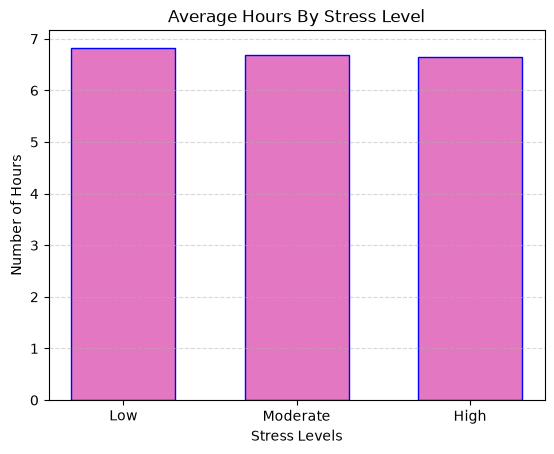

stress_level
Low         6.820930
Moderate    6.682353
High        6.646154
Name: sleep_hours, dtype: float64


In [80]:
df.head()
df["stress_level"] = df["stress_level"].str.strip().str.title()
df["stress_level"] = df["stress_level"].replace({"Very High":"High"})

stressgroups = df.groupby("stress_level")["sleep_hours"].mean()
stressgroups = stressgroups.reindex(["Low","Moderate","High"])

plt.bar(stressgroups.index,stressgroups.values,color="tab:pink",edgecolor="blue",width=0.6)
plt.title("Average Hours By Stress Level")
plt.xlabel("Stress Levels")
plt.ylabel("Number of Hours")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()
print(stressgroups)


focus_level
High        6.639024
Low         6.483673
Moderate    6.973077
Name: sleep_hours, dtype: float64


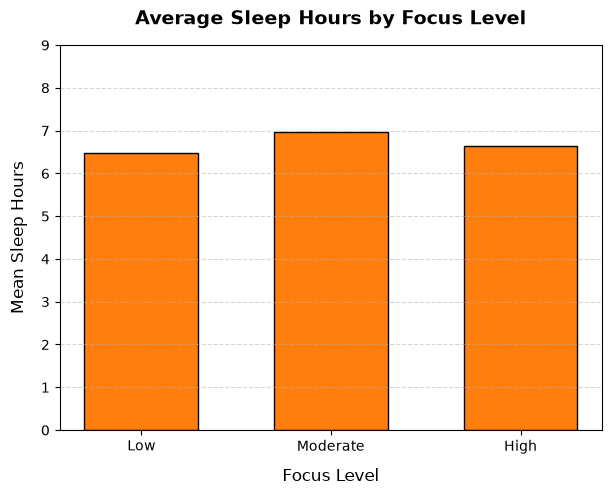


--- Focus Groups Mean Data ---
focus_level
Low         6.483673
Moderate    6.973077
High        6.639024
Name: sleep_hours, dtype: float64


In [81]:
# 1. Group and calculate the mean for focus level
df["focus_level"]=df["focus_level"].replace({"Medium":"Moderate"})
focusgroups = df.groupby("focus_level")["sleep_hours"].mean()
print(focusgroups)

# 2. Reindex to keep the logical order
focusgroups = focusgroups.reindex(["Low", "Moderate", "High"])

# 3. Plot with labels and title
plt.figure(figsize=(7, 5))
plt.bar(focusgroups.index, focusgroups.values, color="tab:orange", edgecolor="black", width=0.6)
plt.title("Average Sleep Hours by Focus Level", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Focus Level", fontsize=12, labelpad=10)
plt.ylabel("Mean Sleep Hours", fontsize=12, labelpad=10)
plt.ylim(0, 9)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

print("\n--- Focus Groups Mean Data ---")
print(focusgroups)


**Question 3: How are sleep hours related to stress level and focus level?**

By looking at bar plots and correlation between focus and sleep, and , stress and sleep this data suggest us that sleep hours are weekly related to focus and stress pattern suggest that increasing or decreasing sleep hours does not guarantee change in focus and stress according to this dataset.